# 2. Linear models
HAR, ARIMA and GARCH forecasts of next week's volatility, evaluated walk-forward over 2021–2026 against the naive forecast.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

rv = pd.read_csv("rv.csv", index_col=0, parse_dates=True)
rv.tail()

,bitcoin,oil,gold,silver
Date,,,,
2026-09-04,0.408360,0.422880,0.277462,0.330438
2026-09-11,0.202442,0.562173,0.111738,0.438367
2026-09-18,0.488885,0.417980,0.141749,0.245413
2026-09-25,0.515967,0.467437,0.128792,0.233922
2026-10-02,0.124664,0.358495,0.270921,0.378746


Load the weekly volatility built in notebook 1.

In [4]:
def har_forecast(y, start="2021"):
    X = pd.DataFrame({"week": y, "month": y.rolling(4).mean(), "quarter": y.rolling(12).mean()})
    X = sm.add_constant(X).shift(1)
    data = pd.concat([y.rename("y"), X], axis=1).dropna()
    preds = {}
    for t in data.loc[start:].index:
        train = data.loc[:t].iloc[:-1]
        fit = sm.OLS(train["y"], train.drop(columns="y")).fit()
        preds[t] = fit.predict(data.loc[[t]].drop(columns="y")).iloc[0]
    return pd.Series(preds)

**HAR model:** next week's volatility regressed on last week's, the 4-week average and the 12-week average. Predictors are shifted by one week (no look-ahead), and the regression is refit every week using past data only (walk-forward testing).

In [5]:
har = pd.DataFrame({c: har_forecast(rv[c]) for c in rv})

test = rv.loc["2021":]
naive = rv.shift(1).loc["2021":]
rmse = lambda f: np.sqrt(((test - f)**2).mean())

pd.DataFrame({"naive": rmse(naive), "HAR": rmse(har)})

,naive,HAR
bitcoin,0.359099,0.275990
oil,0.192272,0.163412
gold,0.100997,0.083447
silver,0.260698,0.202292


HAR beats the naive forecast for every asset, with RMSE 15–23% lower.

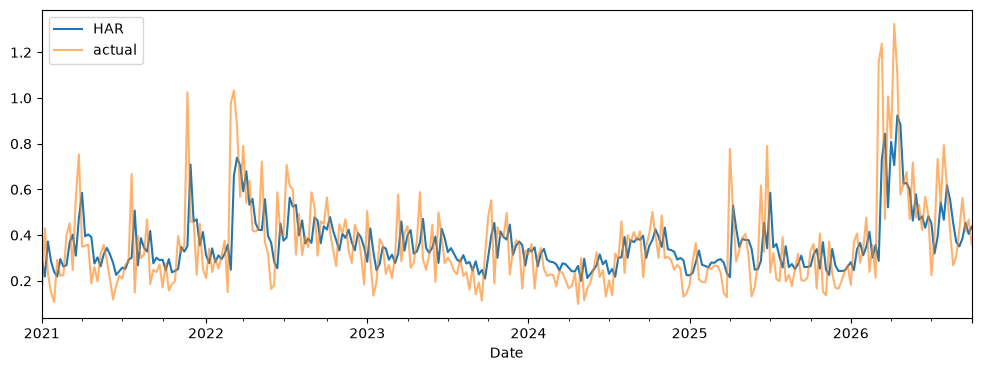

In [6]:
har["oil"].plot(label="HAR", figsize=(12, 4))
test["oil"].plot(label="actual", alpha=0.6)
plt.legend()
plt.show()

HAR forecast vs actual oil volatility over the test period.

In [7]:
import warnings
warnings.filterwarnings("ignore")
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model

Imports for ARIMA and GARCH; convergence warnings are silenced.

In [8]:
def arima_forecast(y, start="2021"):
    ly = np.log(y)
    preds = {}
    for t in y.loc[start:].index:
        fit = ARIMA(ly.loc[:t].iloc[:-1].values, order=(1, 0, 1)).fit()
        preds[t] = np.exp(fit.forecast(1)[0])
    return pd.Series(preds)

arima = pd.DataFrame({c: arima_forecast(rv[c]) for c in rv})

**ARIMA(1,0,1)** on log volatility, refit every week; the forecast is converted back with exp.

In [9]:
returns = pd.read_csv("returns.csv", index_col=0, parse_dates=True)

def garch_forecast(r, weeks, start="2021"):
    preds = {}
    for prev, t in zip(weeks[:-1], weeks[1:]):
        if t < pd.Timestamp(start):
            continue
        fit = arch_model(100 * r.loc[:prev], vol="GARCH", p=1, q=1).fit(disp="off")
        var5 = fit.forecast(horizon=5).variance.iloc[-1].sum()
        preds[t] = np.sqrt(var5) / 100 * np.sqrt(52)
    return pd.Series(preds)

garch = pd.DataFrame({c: garch_forecast(returns[c], rv.index) for c in rv})

**GARCH(1,1)** on daily returns up to the previous Friday. The next 5 daily variance forecasts are summed and converted to the same annualized weekly units as realized volatility.

In [10]:
results = pd.DataFrame({
    "naive": rmse(naive),
    "HAR": rmse(har),
    "ARIMA": rmse(arima),
    "GARCH": rmse(garch),
})
results.round(4)

,naive,HAR,ARIMA,GARCH
bitcoin,0.3591,0.2760,0.2749,0.3206
oil,0.1923,0.1634,0.1681,0.1684
gold,0.1010,0.0834,0.0878,0.0849
silver,0.2607,0.2023,0.2093,0.2165


RMSE of all models over 2021–2026 (lower is better).

In [11]:
results.idxmin(axis=1)

bitcoin    ARIMA
oil          HAR
gold         HAR
silver       HAR
dtype: str

Best linear model per asset: HAR for oil, gold and silver; ARIMA for Bitcoin by a negligible margin.

In [12]:
(1 - results.div(results["naive"], axis=0)) * 100

,naive,HAR,ARIMA,GARCH
bitcoin,0.0,23.143852,23.451023,10.730642
oil,0.0,15.009940,12.562501,12.430848
gold,0.0,17.376850,13.069613,15.950820
silver,0.0,22.403581,19.730785,16.947140


Improvement over the naive forecast, in %. GARCH is the weakest, especially for Bitcoin.

In [13]:
pd.concat({"HAR": har, "ARIMA": arima, "GARCH": garch}, axis=1).to_csv("linear_forecasts.csv")

Save the forecasts for the comparison notebook.